# Hajj pilgrims by season, 2008 to 2026

**How many pilgrims performed Hajj in 2026, how does that compare with 2019, and how has the split between pilgrims from abroad and pilgrims from inside Saudi Arabia changed?**

This notebook reruns the build script, then recomputes the headline figures from the checked figures and asserts that they match the build output.

In [1]:
import subprocess, sys
import pandas as pd
pd.set_option('display.width', 160); pd.set_option('display.max_columns', None)
out = subprocess.run([sys.executable, 'scripts/build_data.py'], capture_output=True, text=True, check=True)
print('\n'.join(out.stdout.splitlines()[:3]))

raw readings: 210 rows from 21 documents; set aside: 4
checked figures: 84; source checks: {'two-publishers': 43, 'same-publisher': 22, 'one-document': 17, 'one-document-plus-rounded-second': 2}
identities: {'pass': 30}; series years: 2008-2026 (17 seasons)


## Data checks

In [2]:
raw = pd.read_csv('data/raw/pilgrim_readings.csv')
fig = pd.read_csv('data/processed/figures_checked.csv')
print('raw rows:', len(raw), '| documents:', raw.source_id.nunique())
print('missing values in value column:', raw.value.isna().sum())
print('readings set aside:')
print(raw[raw.note.fillna('').str.startswith('set aside')][['measure','year','value','source_id']].to_string(index=False))
print()
print(fig.groupby('measure').source_check.value_counts().unstack(fill_value=0))

raw rows: 210 | documents: 21
missing values in value column: 0
readings set aside:
    measure  year  value   source_id
arrival_sea  2024   4741 gastat_2024
      total  2021  58745  saudipedia
      total  2021  58518      hajjto
      total  2020   1000  saudipedia

source_check  one-document  one-document-plus-rounded-second  same-publisher  two-publishers
measure                                                                                     
arrival_air              4                                 0               2               1
arrival_land             4                                 0               2               1
arrival_sea              5                                 0               1               1
external                 0                                 1               6              10
female                   2                                 0               2               2
internal                 0                                 1               7   

In [3]:
ids = pd.read_csv('data/processed/identity_checks.csv')
print(ids.groupby('identity').result.value_counts().unstack(fill_value=0))
assert (ids.result == 'pass').all()

result                       pass
identity                         
air + land + sea = external     7
internal + external = total    17
male + female = total           6


## Recompute the series from the checked figures

In [4]:
f = fig.pivot(index='year', columns='measure', values='value')
s = f.loc[f.internal.notna() & f.external.notna(), ['total','external','internal']].astype(int)
assert (s.internal + s.external == s.total).all()
s['internal_share_pct'] = (s.internal / s.total * 100).round(1)
for m in ['total','external','internal']:
    s[f'{m}_pct_of_2019'] = (s[m] / s.loc[2019, m] * 100).round(1)
built = pd.read_csv('data/processed/pilgrims_by_year.csv').set_index('year')
for c in s.columns:
    assert (s[c] == built[c]).all(), c
print(s)

measure    total  external  internal  internal_share_pct  total_pct_of_2019  external_pct_of_2019  internal_pct_of_2019
year                                                                                                                   
2008     2408849   1729841    679008                28.2               96.8                  93.3                 107.0
2009     2313278   1613965    699313                30.2               92.9                  87.0                 110.2
2010     2789399   1799601    989798                35.5              112.1                  97.0                 156.0
2011     2927717   1828195   1099522                37.6              117.6                  98.6                 173.3
2012     3161573   1752932   1408641                44.6              127.0                  94.5                 222.1
2013     1980249   1379531    600718                30.3               79.5                  74.4                  94.7
2014     2085238   1389053    696185    

## Headline figures

In [5]:
h = pd.read_csv('data/processed/headline_figures.csv').set_index('figure').value
mine = {
 'total_pilgrims_2026': s.loc[2026,'total'],
 'total_change_2025_to_2026_pct': round((s.loc[2026,'total']/s.loc[2025,'total']-1)*100, 1),
 'external_2026_pct_of_2019': s.loc[2026,'external_pct_of_2019'],
 'internal_2026_pct_of_2019': s.loc[2026,'internal_pct_of_2019'],
 'total_2026_pct_of_2019': s.loc[2026,'total_pct_of_2019'],
 'internal_share_2026_pct': s.loc[2026,'internal_share_pct'],
 'internal_share_2019_pct': s.loc[2019,'internal_share_pct'],
 'internal_share_2012_pct': s.loc[2012,'internal_share_pct'],
 'female_share_2026_pct': round(f.loc[2026,'female']/f.loc[2026,'total']*100, 1),
}
for k, v in mine.items():
    assert abs(h[k] - v) < 1e-9, (k, h[k], v)
    print(f'{k:35s} {v}')

total_pilgrims_2026                 1707301
total_change_2025_to_2026_pct       2.0
external_2026_pct_of_2019           83.4
internal_2026_pct_of_2019           25.3
total_2026_pct_of_2019              68.6
internal_share_2026_pct             9.4
internal_share_2019_pct             25.5
internal_share_2012_pct             44.6
female_share_2026_pct               47.7


## Charts

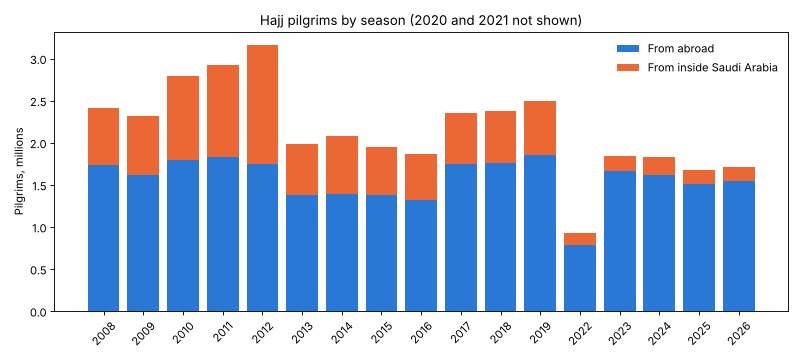

In [6]:
import matplotlib.pyplot as plt
fig1, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(s.index.astype(str), s.external/1e6, label='From abroad', color='#2a78d6')
ax.bar(s.index.astype(str), s.internal/1e6, bottom=s.external/1e6, label='From inside Saudi Arabia', color='#eb6834')
ax.set_ylabel('Pilgrims, millions'); ax.legend(frameon=False); ax.set_title('Hajj pilgrims by season (2020 and 2021 not shown)')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## Foreign pilgrims by origin group

In [7]:
org = pd.read_csv('data/processed/external_by_origin.csv')
print(org.pivot(index='origin_group', columns='year', values='share_pct'))

year                                   2017  2018  2019  2024
origin_group                                                 
Americas and Australia                  1.3   1.4   1.4   NaN
Arab countries (as printed)             NaN   NaN   NaN  22.3
Europe                                  4.8   5.0   3.6   NaN
Europe, Americas, Australia and other   NaN   NaN   NaN   3.2
GCC countries                           1.9   1.9   1.7   NaN
Non-Arab Africa                        10.7   9.4  10.1  11.3
Non-Arab Asia                          59.5  59.7  60.7  63.3
Other Arab countries                   21.9  22.5  22.4   NaN
